# 🧪 LAB: Implement an autoencoder with `PyTorch`

In this lab, you will implement and explore autoencoders using the MNIST dataset. The goal is to understand how autoencoders learn compressed representations of data, and how these representations compare with classical methods like PCA.

**Collaboration Note**: This assignment is designed to support collaborative work. We encourage you to divide tasks among group members so that everyone can contribute meaningfully. Many components of the assignment can be approached in parallel or split logically across team members. Good coordination and thoughtful integration of your work will lead to a stronger final result.

---

In total, this lab assignment will be worth **100 points**.

--- 
**Submission notes**:

* Write down all group members' names, or at least the group name (if you have one and you previously provided it), in the first cell of the notebook.

* Verify that the notebook runs as expected and that all required outputs are included.


NAME(s) = "Kaitlin Luu, Natalie Schweickert, James Torgerson"

## 1. Theoretical Background Reflection (10 points)

Read *Michelucci (2022)*: [An Introduction to Autoencoders](https://arxiv.org/abs/2201.03898) — focus on the following sections:  
- 1. Introduction
- 2.1, 2.2, and 2.3
- Skim Section 3 on applications  

Then answer briefly:

**1. What is the main idea behind an autoencoder?**

The main purpose of an autoencoder is to train an unsupervised neural network to learn a compressed, more efficient representation of input data. In other words, the model learns the patterns and features in the data, and then is encoded to make it compressed. It is then decoded, so that it can reconstruct the input observations $x_{i}$, while maintaining the lowest possible error.

**2. What is the role of the bottleneck layer?**

The role of the bottleneck layer is to enforce a lower-dimensional representation of the input data. It does this by decreasing the number of neurons in the middle layer compared to the input layer, which compresses the data, while still retaining important information. If there was no bottleneck layer, the model would simply just copy the input, which would prevent it from effectively learning and generalizing. 

**3. Discuss, in your own words, the applications of autoencoders mentioned in the paper.**

Firstly, autoencoders are used for dimensionality reduction, which means that they compress input data into a lower dimensional space, which allows it to capture non-linear relationships. Secondly, it is used for classification, which involves training on the compressed features, which is more efficient than if it were training on the raw data. It is also helpful for detecting anomalies since it is able to identify unusually high reconstruction errors. Lastly, autoencoders are trained to denoise data as a result of reconstruction. Reconstruction eliminates noise, such as random errors or unwanted variations. 

**4. What differences would you expect between an autoencoder’s representation and that of PCA if applied as a dimensionality reduction technique?**

We would expect the autoencoder to better represent non-linearity in the data because PCA traditionally only captures linearity. Because autoencoders rely on neural networks, they are more flexible and can learn and preserve more complex transformations and patterns among the features. On the other hand, PCA computes transformations on the entire dataset in one run, which makes it inefficient for large datasets. Overall, PCA is usually simpler and faster to compute, while autoencoders require more training and tuning, but work well on large and complex datasets. 

## 2. Prepare the Data (10 points)

Given the below dataset:

- Normalize **each** image (i.e., separately) so its values are between 0 and 1. Remember our first-week discussions of fixed and fitted transformations.
- Visualize a few random digits to confirm everything worked as expected.
- Split the dataset into fitting, tuning and reporting sets (70%, 15%, 15%).
- Wrap each data splitting as `DataLoader` object with a batch size of 128. Call them `fitting_loader`, `tuning_loader` and `reporting_loader`, respectively.

In [1]:
from sklearn.datasets import fetch_openml
mnist = fetch_openml("mnist_784", version=1, as_frame=False, parser="liac-arff", n_retries=5, delay=2) 
# had to add in parser='liac-arff' becuase it was not working before
X, y = mnist.data, mnist.target.astype(int)

In [2]:
X.max()

np.float64(255.0)

In [3]:
X_scaled = X / 255 
# use this to normalize each image separately so values are between 0 and 1 and you are not learning anything

In [4]:
import numpy as np
# Get unique values and their corresponding counts
values, counts = np.unique(X_scaled[11], return_counts=True)

# Print them side-by-side
for value, count in zip(values, counts):
    print(f"Number: {value} | Count: {count}")

Number: 0.0 | Count: 693
Number: 0.011764705882352941 | Count: 1
Number: 0.023529411764705882 | Count: 1
Number: 0.03137254901960784 | Count: 3
Number: 0.0392156862745098 | Count: 1
Number: 0.047058823529411764 | Count: 1
Number: 0.054901960784313725 | Count: 1
Number: 0.07058823529411765 | Count: 1
Number: 0.07450980392156863 | Count: 1
Number: 0.0784313725490196 | Count: 1
Number: 0.09803921568627451 | Count: 1
Number: 0.11764705882352941 | Count: 1
Number: 0.12156862745098039 | Count: 1
Number: 0.15294117647058825 | Count: 2
Number: 0.1568627450980392 | Count: 1
Number: 0.1607843137254902 | Count: 1
Number: 0.19607843137254902 | Count: 1
Number: 0.21568627450980393 | Count: 1
Number: 0.22745098039215686 | Count: 1
Number: 0.26666666666666666 | Count: 1
Number: 0.27058823529411763 | Count: 1
Number: 0.3058823529411765 | Count: 2
Number: 0.30980392156862746 | Count: 1
Number: 0.3254901960784314 | Count: 1
Number: 0.3607843137254902 | Count: 1
Number: 0.3843137254901961 | Count: 1
Numb

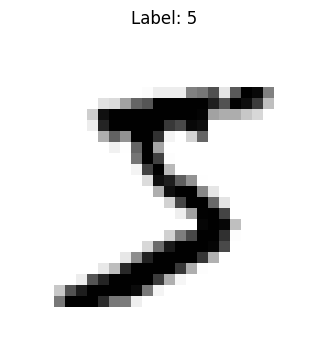

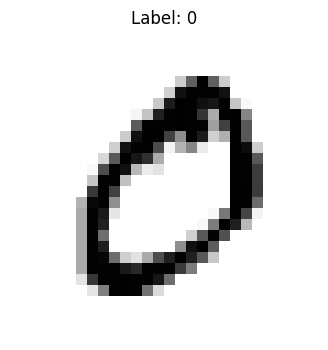

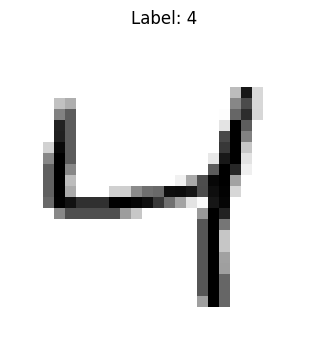

In [5]:
# visualize a single digit
import matplotlib.pyplot as plt

for digit in range(3):
    single_digit = X_scaled[digit]
    single_digit_image = single_digit.reshape(28, 28)

    plt.figure(figsize=(4, 4))
    plt.imshow(single_digit_image, cmap="binary")
    plt.title(f"Label: {y[digit]}")
    plt.axis("off")
    plt.show()

In [6]:
# train test split
from sklearn.model_selection import train_test_split

X_train, X_holdout, y_train, y_holdout = train_test_split(X_scaled, y, test_size=0.3, random_state=1234)

X_tune, X_report, y_tune, y_report = train_test_split(X_holdout, y_holdout, test_size=0.5, random_state=1234)

In [7]:
import torch
# convert to tensors
X_train_tensor = torch.tensor(X_train, dtype=torch.float32)
y_train_tensor = torch.tensor(y_train)

X_tune_tensor = torch.tensor(X_tune, dtype=torch.float32)
y_tune_tensor = torch.tensor(y_tune)

X_report_tensor = torch.tensor(X_report, dtype=torch.float32)
y_report_tensor = torch.tensor(y_report)

In [8]:
from torch.utils.data import DataLoader, TensorDataset
train_dataset = TensorDataset(X_train_tensor, y_train_tensor)
fitting_loader = DataLoader(
    dataset=train_dataset, 
    batch_size=128,      
    shuffle=True,   
)
tune_dataset = TensorDataset(X_tune_tensor, y_tune_tensor)
tuning_loader = DataLoader(
    dataset=tune_dataset, 
    batch_size=128,      
    shuffle=False,   
)
report_dataset = TensorDataset(X_report_tensor, y_report_tensor)
reporting_loader = DataLoader(
    dataset=report_dataset, 
    batch_size=128,      
    shuffle=False,   
)

## 3. Autoencoder

In this section, you will build and train an **autoencoder** to reconstruct the provided data.

Your model will include three layers in both the encoder and decoder:

- **Encoder:** 784 → 128 → 64 → 2. This last layer here is the **bottleneck**.
- **Decoder:** 2 → 64 → 128 → 784  

### 3.1 Implementation (30 points)

Follow the skeleton provided below and fill in the missing parts (`#TODO`). 

Follow these restrictions:

- Each **hidden** layer should include a linear transformation, ReLU activation function, dropout with `p=0.2` and batch normalization steps. Determine the appropriate order for these components based on what we discussed in class. The bottleneck layer is the exception; see next point.
- For the bottleneck, use only a linear transformation, i.e., no activation, batch normalization, or dropout.
- The output layer should have a sigmoid activation function.

In [9]:
import torch.nn as nn

class Autoencoder(nn.Module):
    def __init__(self):
        super().__init__()
        
        # ENCODING PART: 784 -> 128 -> 64 -> 2
        encoder_list = [
            # TODO: Add steps to go from 784 to 128 
            nn.Linear(784,128),
            nn.BatchNorm1d(128),
            nn.ReLU(),
            nn.Dropout(p=0.2),
            # TODO: Add steps to go from 128 to 64 
            nn.Linear(128,64),
            nn.BatchNorm1d(64),
            nn.ReLU(),
            nn.Dropout(p=0.2),
            # TODO: Add steps to go from 64 to 2. 
            nn.Linear(64,2)
        ]
        # TODO: Replace the None value below with the module that stores the layers in 'encoder_list' for manual iteration in the forward pass
        # Hint: we have covered this module in class
        self.encoder_list = nn.ModuleList(encoder_list)
        
        # DECODING PART: 2 -> 64 -> 128 -> 784
        decoder_list = [
            # TODO: Add steps to go from 2 to 64
            nn.Linear(2,64),
            nn.BatchNorm1d(64),
            nn.ReLU(),
            nn.Dropout(p=0.2),
            # TODO: Add steps to go from 64 to 128  
            nn.Linear(64,128),
            nn.BatchNorm1d(128),
            nn.ReLU(),
            nn.Dropout(p=0.2),
            # TODO: Add steps to go from 128 to 784. 
            nn.Linear(128,784),
            nn.Sigmoid(),
        ]
        # TODO: Replace the None value below with the module that stores the layers in 'decoder_list' for manual iteration in the forward pass
        # Hint: we have covered this module in class
        self.decoder_list = nn.ModuleList(decoder_list)
        
    def forward(self, X):
        # TODO: Replace the None value below for that after applying X -> encoder -> decoder
        # Hint: You will probably need to iterate through the encoder_list and decoder_list
        for layer in self.encoder_list:
            X = layer(X)
        for layer in self.decoder_list: 
            X = layer(X)
        output = X
        return output

### 3.2 Training (15 points)

Follow the skeleton provided below and fill in the missing parts to train your model (`#TODO`). As you can see, training includes EarlyStopping, which I give you already for your convenience :-). After you have filled these missing parts, uncomment the provided piece of code with the function for training (`train_autoencoder`) your model and execute it.

But, **BEFORE** that, discuss with your mates and provide elaborated answers to the following:

**Why do you think the output layer of the autoencoder above uses a Sigmoid activation?**

It uses a Sigmoid activation function on the output layer because the original pixel values are normalized between 0 and 1, and using Sigmoid ensures that every output value is also between 0 and 1. This is important because we want the reconstructed pixels to fall in the same range as the original ones. If they aren't within that range, the model might not be able to effectively generate the images. This is especially useful for the MNIST dataset because most pixels are either black (0), white (1), or in between. 


**Based on this, which cost function is most appropriate for this task? Justify your choice.**

The cost function we will use is MSE since it offers the most accurate reconstruction of the original image. MSE works by calculating the squared difference between each original pixel value and its reconstructed value, and then averaging these differences across all pixels. The differences tell us the errors, and the largest errors are then penalized. MSE also allows us to predict continuous values between 0 and 1 rather than trying to classify images into categories. 

Once you have discussed and agreed on the reasoning above, proceed to complete the skeleton (`#TODO`) and train the model.


In [10]:
# TODO: Replace None to instantiate the autoencoder
model = Autoencoder()  

# TODO: Replace None with the appropriate Loss function from 'torch.nn'
# Hint: we are reconstructing continuous pixel values in [0,1]
criterion = nn.MSELoss()  

# TODO: Replace None with Adam optimizer. 
# Use learning rate of 0.001 and an L2 regularization via weight_decay of 1e-5
optimizer = torch.optim.Adam(model.parameters(), lr=0.001, weight_decay=1e-5)  

In [11]:
class EarlyStopping:
    def __init__(self, patience=10, min_delta=0.0):
        self.patience = patience
        self.min_delta = min_delta
        self.counter = 0
        self.best_loss = None
        self.early_stop = False
        self.best_model_state = None

    def __call__(self, tuning_loss, model):
        if self.best_loss is None or tuning_loss < self.best_loss - self.min_delta:
            self.best_loss = tuning_loss
            self.counter = 0
            self.best_model_state = {k: v.clone() for k, v in model.state_dict().items()}
        else:
            self.counter += 1
            if self.counter >= self.patience:
                self.early_stop = True

    def restore_best_weights(self, model):
        if self.best_model_state is not None:
            model.load_state_dict(self.best_model_state)


def train_autoencoder(model, fitting_loader, tuning_loader, n_epochs=100, patience=5):
    # Initialize the early stopping object
    early_stopping = EarlyStopping(patience=patience)
    history = {"fitting": [], "tuning": []}

    for epoch in range(n_epochs):
        model.train()
        fitting_cost = 0.0

        for X_batch, _ in fitting_loader:
            # --- Implement the standard training steps ---
            
            outputs = model(X_batch)            # TODO: Forward pass for this batch
            cost = criterion(outputs, X_batch)  # TODO: Compute the cost for this batch
            cost.backward()                     # TODO: Backward pass (compute gradients)
            optimizer.step()                    # TODO: Update model parameters
            optimizer.zero_grad()               # TODO: Set gradients equal to zero
            fitting_cost += cost.item() * X_batch.size(0)

        fitting_cost /= len(fitting_loader.dataset)

        # --- Tuning phase ---
        model.eval()
        tuning_cost = 0.0
        with torch.no_grad():
            for X_batch, _ in tuning_loader:
                outputs = model(X_batch)            # TODO: Forward pass for tuning data
                cost = criterion(outputs, X_batch)  # TODO: Compute the tuning cost
                tuning_cost += cost.item() * X_batch.size(0)

        tuning_cost /= len(tuning_loader.dataset)

        # --- Save metrics ---
        history["fitting"].append(fitting_cost)
        history["tuning"].append(tuning_cost)

        print(f"Epoch [{epoch+1}/{n_epochs}]  Fitting Cost: {fitting_cost:.5f}  Tuning Cost: {tuning_cost:.5f}")

        # --- Early stopping check ---
        early_stopping(tuning_cost, model)
        if early_stopping.early_stop:
            print(f"Stopping early at epoch {epoch+1}")
            early_stopping.restore_best_weights(model)
            return model, history

    return model, history


Once the missing parts have been filled, uncomment the piece of code below and execute it to train your model (it may take a bit to complete the training, which is totally normal).

In [12]:
model, history = train_autoencoder(model, fitting_loader, tuning_loader, n_epochs=50, patience=5)

Epoch [1/50]  Fitting Cost: 0.06409  Tuning Cost: 0.04993
Epoch [2/50]  Fitting Cost: 0.05081  Tuning Cost: 0.04772
Epoch [3/50]  Fitting Cost: 0.04945  Tuning Cost: 0.04679
Epoch [4/50]  Fitting Cost: 0.04892  Tuning Cost: 0.04630
Epoch [5/50]  Fitting Cost: 0.04852  Tuning Cost: 0.04568
Epoch [6/50]  Fitting Cost: 0.04827  Tuning Cost: 0.04546
Epoch [7/50]  Fitting Cost: 0.04807  Tuning Cost: 0.04516
Epoch [8/50]  Fitting Cost: 0.04790  Tuning Cost: 0.04503
Epoch [9/50]  Fitting Cost: 0.04778  Tuning Cost: 0.04483
Epoch [10/50]  Fitting Cost: 0.04766  Tuning Cost: 0.04455
Epoch [11/50]  Fitting Cost: 0.04760  Tuning Cost: 0.04464
Epoch [12/50]  Fitting Cost: 0.04752  Tuning Cost: 0.04452
Epoch [13/50]  Fitting Cost: 0.04748  Tuning Cost: 0.04452
Epoch [14/50]  Fitting Cost: 0.04736  Tuning Cost: 0.04445
Epoch [15/50]  Fitting Cost: 0.04730  Tuning Cost: 0.04416
Epoch [16/50]  Fitting Cost: 0.04732  Tuning Cost: 0.04427
Epoch [17/50]  Fitting Cost: 0.04727  Tuning Cost: 0.04420
Epoch 

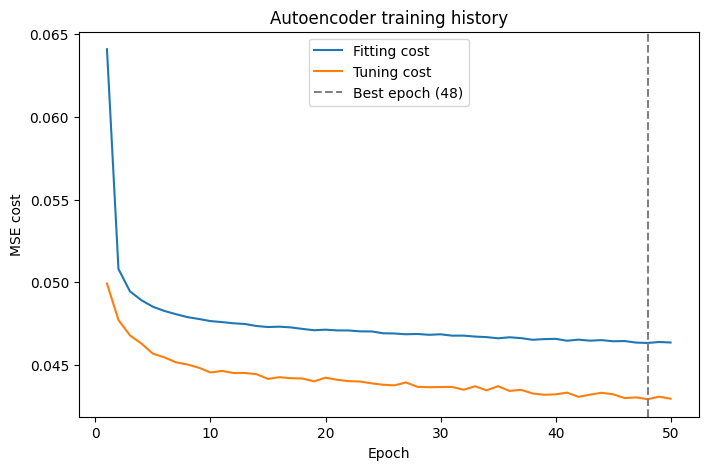

Best tuning cost: 0.04293 at epoch 48


In [13]:
# plot the training history

import matplotlib.pyplot as plt

epochs = range(1, len(history["fitting"]) + 1)
best_epoch = int(np.argmin(history["tuning"])) + 1

plt.figure(figsize=(8, 5))

# learning curves that display cost on the fitting set vs. the tuning set after each epoch
plt.plot(epochs, history["fitting"], label="Fitting cost")
plt.plot(epochs, history["tuning"], label="Tuning cost")

# line to show the best epoch (lowest tuning cost)
plt.axvline(best_epoch, color="gray", linestyle="--", label=f"Best epoch ({best_epoch})")

plt.xlabel("Epoch")
plt.ylabel("MSE cost")
plt.title("Autoencoder training history")
plt.legend()
plt.show()

print(f"Best tuning cost: {min(history['tuning']):.5f} at epoch {best_epoch}")

The graph shows that the training did what it was supposed to do and converged. Both the fitting and tuning costs drop sharply after the first few epochs and then eventually level off. There is also no overfitting, as shown by the tuning cost being lower than the fitting cost, and the fact that the lines stay relatively close together. 

### 3.3 Reconstruct (5 points)

Once you have trained the model: 

1. Visualize several reconstructed digits from the reporting set.  
2. Compare them with the corresponding original input digits. Was the reconstruction good? 

In [14]:
# select samples for reconstruction
sample_inputs = X_report_tensor[:3]
sample_labels = y_report_tensor[:3]

with torch.no_grad():
    sample_reconstructions = model(sample_inputs)

# convert to numpy for plotting
inputs_np = sample_inputs.numpy()
reconstructions_np = sample_reconstructions.numpy()

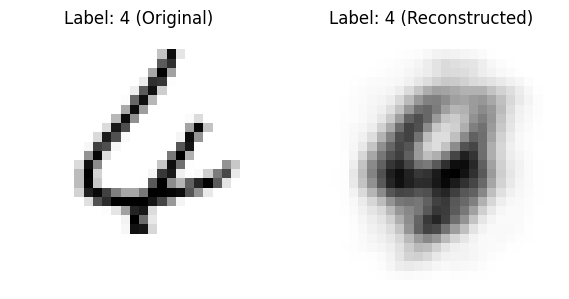

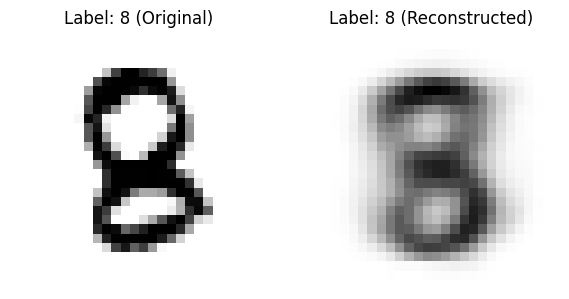

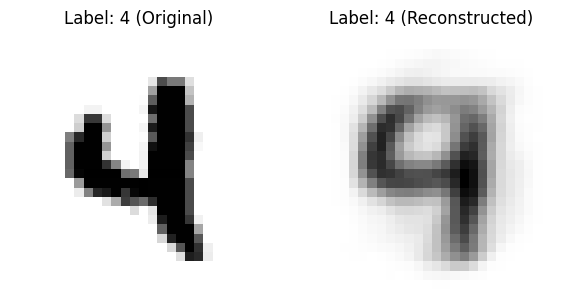

In [15]:
# USE AS MANY CELLS AS NEEDED
for i in range(3):
    original_image = inputs_np[i].reshape(28, 28)
    reconstructed_image = reconstructions_np[i].reshape(28, 28)
    label = sample_labels[i].item()

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(6, 3))

    # Plot original input
    ax1.imshow(original_image, cmap="binary")
    ax1.set_title(f"Label: {label} (Original)")
    ax1.axis("off")

    # Plot reconstructed output
    ax2.imshow(reconstructed_image, cmap="binary")
    ax2.set_title(f"Label: {label} (Reconstructed)")
    ax2.axis("off")

    plt.tight_layout()
    plt.show()

Compared to the initial visual inputs, the reconstructions are much blurrier, to the degree that it makes them resemble other numbers. For example, from this selection, the reconstructed 4s resemble 9s, and the reconstructed 8 resembles a 3. So, while the reconstruction *can* be understood as the actual label, they are less clear, and therefore are slightly worse representations.

## 4. Visualize the Learned Representations (15 points)

Here you will explore the latent representations learned by your autoencoder.

1. Complete `extract_latent_features` to extract the latent (bottleneck) features and their corresponding labels, given a trained model.  
   Apply this function to the reporting set using the provided code. This should give you the transformed reporting set with the dimensions of the bottleneck (2).
2. Plot the reduced 2D data as a scatterplot, coloring each point by its corresponding digit label.


In [16]:
def extract_latent_features(model, dataloader): 
    model.eval()
    latents = []
    labels = []

    with torch.no_grad():
        for X_batch, y_batch in dataloader:
            
            encoded = X_batch  # TODO: Apply the encoder part of the model to get the latent features
            for layer in model.encoder_list:
                encoded = layer(encoded)
            latents.append(encoded.numpy())
            labels.append(y_batch.numpy())

    # Concatenate all batches
    latents = np.concatenate(latents, axis=0)
    labels = np.concatenate(labels, axis=0)
    return latents, labels

Once the missing parts above have been filled, uncomment the piece of code below and execute it to extract the latent features

In [17]:
latents_autoencoder, labels = extract_latent_features(model, reporting_loader)

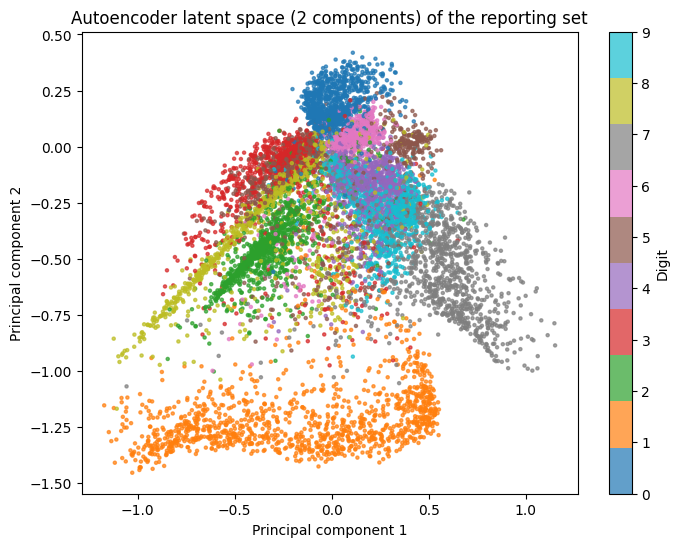

In [18]:
# scatterplot colored by digit
plt.figure(figsize=(8, 6))
sc = plt.scatter(latents_autoencoder[:, 0],latents_autoencoder[:, 1], c=labels, cmap="tab10", s=5, alpha=0.7)
plt.colorbar(sc, ticks=range(10), label="Digit")
plt.title("Autoencoder latent space (2 components) of the reporting set")
plt.xlabel("Principal component 1")
plt.ylabel("Principal component 2")
plt.show()

## 5. Compare with PCA (10 points)

Here you will compare the latent representations learned by your autoencoder with those obtained using a PCA.

1. Apply a PCA to the reporting set (without using the autoencoder) to reduce the data to the same dimensionality as your bottleneck (2 dimensions). Obviously, first use the rest of the data to learn these two components.
2. Visualize the reduced 2D data as a scatterplot, coloring each point by its corresponding digit label.
3. Compare the structure of the two plots (Autoencoder vs. PCA) and briefly discuss the differences (if any) you observe.

Explained variance (2 PCs): 0.1692754


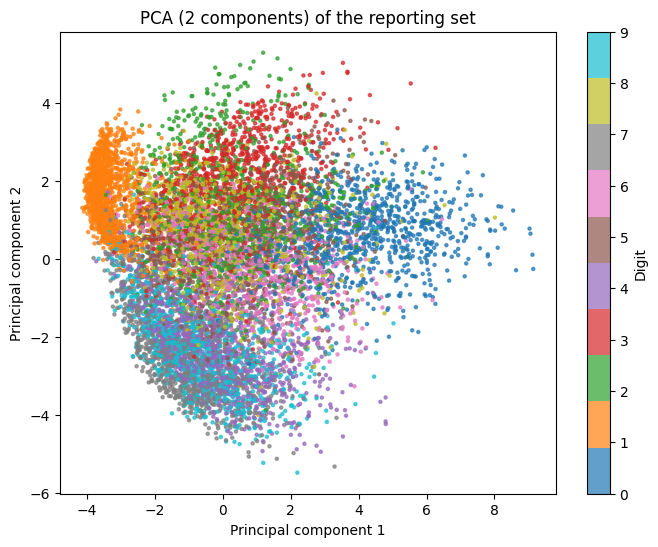

In [19]:
from sklearn.decomposition import PCA

# learn the two components on train and tune 
X_rest = torch.cat([X_train_tensor, X_tune_tensor]).cpu().numpy()
X_report_np = X_report_tensor.cpu().numpy()
y_report_np = y_report_tensor.cpu().numpy()

# PCA 2 components 
pca = PCA(n_components=2)
pca.fit(X_rest)

# apply to the reporting set
Z_pca = pca.transform(X_report_np)
print("Explained variance (2 PCs):", pca.explained_variance_ratio_.sum())

# scatterplot colored by digit
plt.figure(figsize=(8, 6))
sc = plt.scatter(Z_pca[:, 0], Z_pca[:, 1], c=y_report_np, cmap="tab10", s=5, alpha=0.7)
plt.colorbar(sc, ticks=range(10), label="Digit")
plt.title("PCA (2 components) of the reporting set")
plt.xlabel("Principal component 1")
plt.ylabel("Principal component 2")
plt.show()

Compared to the autoencoder, PCA was much worse at differentiating between different digits. There is much more overlap between digits on PCA, with very few being in distinguishable clusters, where as with the autoencoder, there is much more visual separation between digit clusters, and of the ones that overlap, it is because the digits themselves are generally visually similar (e.g., 3 and 8, or 4 and 9). So, while there is still overlap present with the autoencoder plot, it is significantly less than with PCA, and seems to have more regularity with when the overlap occurs. 

## 6. Collaboration Reflection (5 points)

As a group, identify **one specific challenge or inefficiency** you encountered while working on this lab. In 3–5 sentences:

1. Briefly describe what happened and how it affected your work.
2. Identify one concrete action your group will take to avoid or better manage this issue in the next lab.

If your group encountered no major problem, identify one aspect of your collaboration that could still be improved.

We didn't have any significant challenges with the lab itself, but one inefficiency we faced was its overlap with our Data Engineering project. Both assignments were due around the same time, which hindered our ability to get the lab quickly like we usually do. In the future, we will focus on prioritizing tasks and managing our time more effectively to balance multiple important assignments.